# 1. 환경 설정, 모델 정의 및 학습 전 영상 생성
이 단계에서는 무작위 초기화된 Actor-Critic 모델로 행동을 선택합니다. 따라서 첫 영상은 학습된 정책이 아닌 초기 정책의 행동을 보여줍니다.

In [1]:

import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import random
import threading
from pathlib import Path

import cv2
import gymnasium as gym
import ale_py
import imageio.v2 as imageio
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.distributions import Categorical
from gymnasium.wrappers import AtariPreprocessing, FrameStackObservation
from IPython.display import display, HTML

gym.register_envs(ale_py)

SEED = 7
NUM_WORKERS = 4
MAX_EPISODES = 10000
N_STEPS = 5
GAMMA = 0.99
LR = 1e-4
ENTROPY_COEF = 0.01
VALUE_COEF = 0.5
MAX_GRAD_NORM = 40.0
VIDEO_SECONDS = 10
VIDEO_FPS = 15
OUT = Path("a3c_breakout_results")
OUT.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class ActorCritic(nn.Module):
    def __init__(self, n_actions):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(4, 32, 8, stride=4),
            nn.ReLU(),
            nn.Conv2d(32, 64, 4, stride=2),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, stride=1),
            nn.ReLU(),
            nn.Flatten()
        )
        self.fc = nn.Linear(64 * 7 * 7, 512)
        self.actor = nn.Linear(512, n_actions)
        self.critic = nn.Linear(512, 1)

        for layer in self.modules():
            if isinstance(layer, (nn.Conv2d, nn.Linear)):
                nn.init.orthogonal_(layer.weight, gain=np.sqrt(2))
                nn.init.constant_(layer.bias, 0.0)

        nn.init.orthogonal_(self.actor.weight, gain=0.01)
        nn.init.orthogonal_(self.critic.weight, gain=1.0)

    def forward(self, x):
        x = x.float() / 255.0
        x = self.conv(x)
        x = F.relu(self.fc(x))
        return self.actor(x), self.critic(x).squeeze(-1)


def make_env(seed):
    env = gym.make(
        "ALE/Breakout-v5",
        frameskip=1,
        repeat_action_probability=0.0,
        render_mode="rgb_array"
    )
    env = AtariPreprocessing(
        env,
        noop_max=30,
        frame_skip=4,
        screen_size=84,
        terminal_on_life_loss=False,
        grayscale_obs=True,
        scale_obs=False
    )
    env = FrameStackObservation(env, stack_size=4)
    env.action_space.seed(seed)
    return env


def choose_action(model, obs, deterministic=False):
    state = torch.as_tensor(
        np.asarray(obs),
        dtype=torch.float32,
        device=DEVICE
    ).unsqueeze(0)

    with torch.no_grad():
        logits, _ = model(state)
        if deterministic:
            return int(logits.argmax(dim=-1).item())
        return int(Categorical(logits=logits).sample().item())


def record_episode(model, filename, seed):
    env = make_env(seed)
    obs, _ = env.reset(seed=seed)
    frames = []
    total_reward = 0.0
    max_steps = VIDEO_SECONDS * VIDEO_FPS
    done = False

    while len(frames) < max_steps and not done:
        action = choose_action(model, obs, deterministic=True)
        obs, reward, terminated, truncated, _ = env.step(action)
        total_reward += float(reward)
        done = terminated or truncated

        frame = env.render()
        if frame is None:
            frame = cv2.cvtColor(
                np.asarray(obs[-1]),
                cv2.COLOR_GRAY2RGB
            )

        frames.append(np.asarray(frame, dtype=np.uint8))

    env.close()

    if not frames:
        raise RuntimeError(f"No frames recorded: {filename}")

    frames.extend([frames[-1]] * (max_steps - len(frames)))

    imageio.mimsave(
        filename,
        frames[:max_steps],
        fps=VIDEO_FPS,
        macro_block_size=1
    )

    return total_reward


probe = make_env(SEED)
N_ACTIONS = probe.action_space.n
probe.close()

model = ActorCritic(N_ACTIONS).to(DEVICE)

initial_video = OUT / "episode_1.mp4"
initial_reward = record_episode(
    model,
    str(initial_video),
    SEED + 100
)

print(f"Initial episode reward: {initial_reward:.2f}")
print(f"Initial video: {initial_video}")
print(f"Device: {DEVICE}")


A.L.E: Arcade Learning Environment (version 0.11.2+ecc1138)
[Powered by Stella]


Initial episode reward: 0.00
Initial video: a3c_breakout_results/episode_1.mp4
Device: cuda


# 2단계. A3C 학습 및 Reward/Loss 기록
각 워커가 5-step rollout을 수행하고, 누적 보상과 가치 추정치를 이용해 정책 손실과 가치 손실을 계산합니다. 학습 진행 상황을 10 에피소드마다 출력합니다.

In [ ]:

class SharedTrainer:
    def __init__(self, n_actions):
        self.model = ActorCritic(n_actions).to(DEVICE)
        self.optimizer = torch.optim.Adam(
            self.model.parameters(),
            lr=7e-4,
            eps=1e-5
        )
        self.optimizer_lock = threading.Lock()
        self.progress_lock = threading.Lock()
        self.completed_episodes = 0
        self.rewards = []
        self.losses = []
        self.policy_losses = []
        self.value_losses = []
        self.entropy_values = []
        self.stop = threading.Event()

    def worker(self, worker_id):
        env = make_env(SEED + worker_id + 1)
        local_model = ActorCritic(N_ACTIONS).to(DEVICE)
        local_model.load_state_dict(self.model.state_dict())
        obs, _ = env.reset(seed=SEED + worker_id + 1)
        episode_reward = 0.0
        local_episode = 0

        while not self.stop.is_set():
            rewards = []
            dones = []
            log_probs = []
            values = []
            entropies = []

            for _ in range(N_STEPS):
                state = torch.as_tensor(
                    np.asarray(obs),
                    dtype=torch.float32,
                    device=DEVICE
                ).unsqueeze(0)

                logits, value = local_model(state)
                dist = Categorical(logits=logits)
                action_tensor = dist.sample()
                action = int(action_tensor.item())

                next_obs, reward, terminated, truncated, _ = env.step(action)
                done = terminated or truncated

                rewards.append(float(np.clip(reward, -1.0, 1.0)))
                dones.append(done)
                log_probs.append(dist.log_prob(action_tensor))
                values.append(value.squeeze(0))
                entropies.append(dist.entropy().mean())

                episode_reward += float(reward)
                obs = next_obs

                if done:
                    break

            with torch.no_grad():
                if dones[-1]:
                    bootstrap = torch.zeros((), device=DEVICE)
                else:
                    state = torch.as_tensor(
                        np.asarray(obs),
                        dtype=torch.float32,
                        device=DEVICE
                    ).unsqueeze(0)
                    _, bootstrap_value = local_model(state)
                    bootstrap = bootstrap_value.squeeze(0)

            returns = []
            R = bootstrap

            for reward, done in zip(reversed(rewards), reversed(dones)):
                R = torch.tensor(
                    reward,
                    dtype=torch.float32,
                    device=DEVICE
                ) + GAMMA * R * (0.0 if done else 1.0)
                returns.append(R)

            returns.reverse()
            returns = torch.stack(returns)
            values_t = torch.stack(values)
            log_probs_t = torch.stack(log_probs)
            entropies_t = torch.stack(entropies)
            advantages = returns - values_t

            policy_loss = -(log_probs_t * advantages.detach()).mean()
            value_loss = advantages.pow(2).mean()
            entropy_loss = entropies_t.mean()
            loss = (
                policy_loss
                + VALUE_COEF * value_loss
                - ENTROPY_COEF * entropy_loss
            )

            local_model.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                local_model.parameters(),
                MAX_GRAD_NORM
            )

            with self.optimizer_lock:
                self.optimizer.zero_grad(set_to_none=True)

                for global_param, local_param in zip(
                    self.model.parameters(),
                    local_model.parameters()
                ):
                    if local_param.grad is not None:
                        global_param.grad = local_param.grad.detach().clone()

                self.optimizer.step()
                local_model.load_state_dict(self.model.state_dict())

            with self.progress_lock:
                self.losses.append(float(loss.detach().cpu()))
                self.policy_losses.append(float(policy_loss.detach().cpu()))
                self.value_losses.append(float(value_loss.detach().cpu()))
                self.entropy_values.append(float(entropy_loss.detach().cpu()))

            if dones[-1]:
                local_episode += 1

                with self.progress_lock:
                    self.completed_episodes += 1
                    self.rewards.append(episode_reward)
                    completed = self.completed_episodes

                    if completed % 10 == 0:
                        recent = np.mean(self.rewards[-10:])
                        print(
                            f"Episodes {completed}/{MAX_EPISODES} "
                            f"| Worker {worker_id} "
                            f"| Mean reward: {recent:.2f}"
                        )

                    if completed >= MAX_EPISODES:
                        self.stop.set()

                episode_reward = 0.0
                obs, _ = env.reset(
                    seed=SEED + worker_id * 100000 + local_episode
                )

        env.close()


trainer = SharedTrainer(N_ACTIONS)

workers = [
    threading.Thread(
        target=trainer.worker,
        args=(i,),
        daemon=True
    )
    for i in range(NUM_WORKERS)
]

for worker in workers:
    worker.start()

for worker in workers:
    worker.join()

model = trainer.model

model_path = OUT / "a3c_breakout_final.pt"
torch.save(model.state_dict(), model_path)

np.save(OUT / "episode_rewards.npy", np.asarray(trainer.rewards))
np.save(OUT / "training_losses.npy", np.asarray(trainer.losses))

print(f"Training completed: {len(trainer.rewards)} episodes")
print(f"Model saved: {model_path}")


Episodes 10/10000 | Worker 3 | Mean reward: 1.30
Episodes 20/10000 | Worker 0 | Mean reward: 1.50
Episodes 30/10000 | Worker 3 | Mean reward: 0.90
Episodes 40/10000 | Worker 3 | Mean reward: 1.90
Episodes 50/10000 | Worker 1 | Mean reward: 2.20
Episodes 60/10000 | Worker 1 | Mean reward: 1.10
Episodes 70/10000 | Worker 0 | Mean reward: 1.00
Episodes 80/10000 | Worker 1 | Mean reward: 0.80
Episodes 90/10000 | Worker 1 | Mean reward: 1.20
Episodes 100/10000 | Worker 1 | Mean reward: 1.40
Episodes 110/10000 | Worker 0 | Mean reward: 1.30
Episodes 120/10000 | Worker 3 | Mean reward: 0.90
Episodes 130/10000 | Worker 1 | Mean reward: 0.80
Episodes 140/10000 | Worker 0 | Mean reward: 0.90
Episodes 150/10000 | Worker 3 | Mean reward: 1.40
Episodes 160/10000 | Worker 0 | Mean reward: 1.00
Episodes 170/10000 | Worker 0 | Mean reward: 1.10
Episodes 180/10000 | Worker 0 | Mean reward: 1.50
Episodes 190/10000 | Worker 0 | Mean reward: 1.20
Episodes 200/10000 | Worker 3 | Mean reward: 1.50
Episodes 

In [ ]:

trained_video = OUT / "trained_episode.mp4"

trained_reward = record_episode(
    model,
    str(trained_video),
    SEED + 200
)

rewards = np.asarray(trainer.rewards, dtype=float)
losses = np.asarray(trainer.losses, dtype=float)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

axes[0, 0].plot(rewards, alpha=0.35, label="Episode reward")

if len(rewards) >= 20:
    moving = np.convolve(
        rewards,
        np.ones(20) / 20,
        mode="valid"
    )
    axes[0, 0].plot(
        np.arange(19, len(rewards)),
        moving,
        label="20-episode moving average"
    )

axes[0, 0].set_title("A3C Breakout - Episode Reward")
axes[0, 0].set_xlabel("Episode")
axes[0, 0].set_ylabel("Reward")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

axes[0, 1].plot(losses, alpha=0.35, label="Total loss")

if len(losses) >= 100:
    window = 100
    moving_loss = np.convolve(
        losses,
        np.ones(window) / window,
        mode="valid"
    )
    axes[0, 1].plot(
        np.arange(window - 1, len(losses)),
        moving_loss,
        label="100-update moving average"
    )

axes[0, 1].set_title("A3C - Training Loss")
axes[0, 1].set_xlabel("Training update")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

axes[1, 0].plot(trainer.policy_losses, label="Policy loss")
axes[1, 0].plot(trainer.value_losses, label="Value loss")
axes[1, 0].set_title("Policy and Value Loss")
axes[1, 0].set_xlabel("Training update")
axes[1, 0].set_ylabel("Loss")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

axes[1, 1].plot(trainer.entropy_values, label="Policy entropy")
axes[1, 1].set_title("Policy Entropy")
axes[1, 1].set_xlabel("Training update")
axes[1, 1].set_ylabel("Entropy")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUT / "training_metrics.png", dpi=160)
plt.show()

initial_uri = initial_video.resolve().as_uri()
trained_uri = trained_video.resolve().as_uri()

display(HTML(f"""
<div style="display:flex; gap:16px; align-items:flex-start; width:100%;">
  <div style="flex:1; min-width:0;">
    <h3>Before Training</h3>
    <video src="{initial_uri}" controls loop style="width:100%;"></video>
    <p>Initial reward: {initial_reward:.2f}</p>
  </div>
  <div style="flex:1; min-width:0;">
    <h3>After Training</h3>
    <video src="{trained_uri}" controls loop style="width:100%;"></video>
    <p>Trained reward: {trained_reward:.2f}</p>
  </div>
</div>
"""))

print(f"Initial video: {initial_video.resolve()}")
print(f"Trained video: {trained_video.resolve()}")
print(f"Metrics plot: {(OUT / 'training_metrics.png').resolve()}")
print(f"Model: {model_path.resolve()}")
print(f"Initial evaluation reward: {initial_reward:.2f}")
print(f"Trained evaluation reward: {trained_reward:.2f}")


Available actions: ['NOOP', 'FIRE', 'RIGHT', 'LEFT']
Device: cuda
Frame shape: (210, 160, 3)
Frames: 450
Total reward: 13.0
Source duration: 30.0 seconds
Playback speed: 2x
Playback duration: 15.0 seconds
Video path: /home/Data_Drive_8TB/kykim/0. Jupyter/RL/a3c_breakout_results/trained_episode_30s_1.5x.mp4


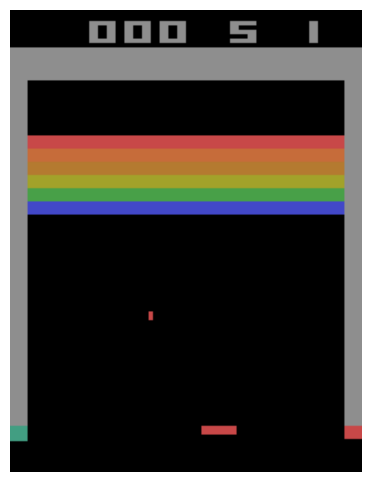

In [6]:

import os
os.environ["OMP_NUM_THREADS"] = "1"

import gymnasium as gym
import ale_py
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import imageio.v2 as imageio
import matplotlib.pyplot as plt
from pathlib import Path
from gymnasium.wrappers import AtariPreprocessing, FrameStackObservation
from IPython.display import display, Video

gym.register_envs(ale_py)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_PATH = Path("/home/Data_Drive_8TB/kykim/0. Jupyter/RL/a3c_breakout_results/a3c_breakout_final.pt")
OUT = MODEL_PATH.parent
VIDEO_PATH = OUT / "trained_episode_30s_1.5x.mp4"
VIDEO_SECONDS = 30
VIDEO_FPS = 15
PLAYBACK_SPEED = 2

class ActorCritic(nn.Module):
    def __init__(self, n_actions):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(4, 32, 8, stride=4),
            nn.ReLU(),
            nn.Conv2d(32, 64, 4, stride=2),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, stride=1),
            nn.ReLU(),
            nn.Flatten()
        )
        self.fc = nn.Linear(64 * 7 * 7, 512)
        self.actor = nn.Linear(512, n_actions)
        self.critic = nn.Linear(512, 1)

    def forward(self, x):
        x = x.float() / 255.0
        x = self.conv(x)
        x = F.relu(self.fc(x))
        return self.actor(x), self.critic(x).squeeze(-1)

def choose_action(model, obs):
    state = torch.as_tensor(
        np.asarray(obs),
        dtype=torch.float32,
        device=DEVICE
    ).unsqueeze(0)
    with torch.no_grad():
        logits, _ = model(state)
    return int(logits.argmax(dim=-1).item())

if not MODEL_PATH.exists():
    raise FileNotFoundError(str(MODEL_PATH))

base_env = gym.make(
    "ALE/Breakout-v5",
    frameskip=1,
    repeat_action_probability=0.0,
    render_mode="rgb_array"
)

action_meanings = base_env.unwrapped.get_action_meanings()
print("Available actions:", action_meanings)

if "FIRE" not in action_meanings:
    base_env.close()
    raise RuntimeError("FIRE action is unavailable in this environment.")

fire_action = action_meanings.index("FIRE")

env = AtariPreprocessing(
    base_env,
    noop_max=0,
    frame_skip=4,
    screen_size=84,
    terminal_on_life_loss=False,
    grayscale_obs=True,
    scale_obs=False
)
env = FrameStackObservation(env, stack_size=4)

model = ActorCritic(env.action_space.n).to(DEVICE)
model.load_state_dict(
    torch.load(MODEL_PATH, map_location=DEVICE, weights_only=True)
)
model.eval()

obs, _ = env.reset(seed=207)
frames = []
total_reward = 0.0
max_steps = VIDEO_SECONDS * VIDEO_FPS

for _ in range(3):
    obs, reward, terminated, truncated, _ = env.step(fire_action)
    total_reward += float(reward)
    if terminated or truncated:
        obs, _ = env.reset()

for _ in range(max_steps):
    action = choose_action(model, obs)
    obs, reward, terminated, truncated, _ = env.step(action)
    total_reward += float(reward)

    frame = base_env.render()
    if frame is not None:
        frames.append(np.asarray(frame, dtype=np.uint8))

    if terminated or truncated:
        obs, _ = env.reset()
        obs, reward, terminated, truncated, _ = env.step(fire_action)
        total_reward += float(reward)

env.close()

if not frames:
    raise RuntimeError("No RGB frames were captured.")

output_fps = VIDEO_FPS * PLAYBACK_SPEED

imageio.mimsave(
    VIDEO_PATH,
    frames,
    fps=output_fps,
    macro_block_size=1
)

print("Device:", DEVICE)
print("Frame shape:", frames[0].shape)
print("Frames:", len(frames))
print("Total reward:", total_reward)
print("Source duration:", round(len(frames) / VIDEO_FPS, 2), "seconds")
print("Playback speed:", f"{PLAYBACK_SPEED}x")
print("Playback duration:", round(len(frames) / output_fps, 2), "seconds")
print("Video path:", VIDEO_PATH)

plt.figure(figsize=(10, 6))
plt.imshow(frames[0])
plt.axis("off")
plt.show()

display(
    Video(
        str(VIDEO_PATH.resolve()),
        embed=True,
        width=800
    )
)


In [3]:

import cv2
import numpy as np
from pathlib import Path
from IPython.display import display, Video

OUT = Path("/home/Data_Drive_8TB/kykim/0. Jupyter/RL/a3c_breakout_results")
VIDEO_LEFT = OUT / "episode_1.mp4"
VIDEO_RIGHT = OUT / "trained_episode_30s_1.5x.mp4"
VIDEO_OUT = OUT / "comparison_episode_1_vs_10000.mp4"

OUTPUT_FPS = 15
PANEL_WIDTH = 640
PANEL_HEIGHT = 360
HEADER_HEIGHT = 50

for path in [VIDEO_LEFT, VIDEO_RIGHT]:
    if not path.exists():
        raise FileNotFoundError(f"Video not found: {path}")

def read_video(path):
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        raise RuntimeError(f"Could not open video: {path}")

    fps = cap.get(cv2.CAP_PROP_FPS)
    frames = []

    while True:
        ret, frame = cap.read()
        if not ret:
            break
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frames.append(frame)

    cap.release()

    if not frames:
        raise RuntimeError(f"No frames found: {path}")

    return frames, fps

def resize_frame(frame, width, height):
    h, w = frame.shape[:2]
    scale = min(width / w, height / h)
    new_w = int(w * scale)
    new_h = int(h * scale)
    resized = cv2.resize(frame, (new_w, new_h), interpolation=cv2.INTER_AREA)
    canvas = np.zeros((height, width, 3), dtype=np.uint8)
    x = (width - new_w) // 2
    y = (height - new_h) // 2
    canvas[y:y + new_h, x:x + new_w] = resized
    return canvas

left_frames, left_fps = read_video(VIDEO_LEFT)
right_frames, right_fps = read_video(VIDEO_RIGHT)

left_duration = len(left_frames) / left_fps if left_fps > 0 else len(left_frames) / OUTPUT_FPS
right_duration = len(right_frames) / right_fps if right_fps > 0 else len(right_frames) / OUTPUT_FPS
duration = max(left_duration, right_duration)
total_frames = int(round(duration * OUTPUT_FPS))

left_indices = np.minimum(
    (np.arange(total_frames) * len(left_frames) / total_frames).astype(int),
    len(left_frames) - 1
)
right_indices = np.minimum(
    (np.arange(total_frames) * len(right_frames) / total_frames).astype(int),
    len(right_frames) - 1
)

output_width = PANEL_WIDTH * 2
output_height = PANEL_HEIGHT + HEADER_HEIGHT

writer = cv2.VideoWriter(
    str(VIDEO_OUT),
    cv2.VideoWriter_fourcc(*"mp4v"),
    OUTPUT_FPS,
    (output_width, output_height)
)

if not writer.isOpened():
    raise RuntimeError(f"Could not create output video: {VIDEO_OUT}")

for i in range(total_frames):
    left = resize_frame(left_frames[left_indices[i]], PANEL_WIDTH, PANEL_HEIGHT)
    right = resize_frame(right_frames[right_indices[i]], PANEL_WIDTH, PANEL_HEIGHT)

    canvas = np.zeros((output_height, output_width, 3), dtype=np.uint8)
    canvas[HEADER_HEIGHT:, :PANEL_WIDTH] = left
    canvas[HEADER_HEIGHT:, PANEL_WIDTH:] = right

    cv2.putText(
        canvas,
        "Episode 1",
        (PANEL_WIDTH // 2 - 75, 34),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.9,
        (255, 255, 255),
        2,
        cv2.LINE_AA
    )

    cv2.putText(
        canvas,
        "Episode 10000",
        (PANEL_WIDTH + PANEL_WIDTH // 2 - 120, 34),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.9,
        (255, 255, 255),
        2,
        cv2.LINE_AA
    )

    cv2.line(
        canvas,
        (PANEL_WIDTH, 0),
        (PANEL_WIDTH, output_height),
        (180, 180, 180),
        2
    )

    writer.write(cv2.cvtColor(canvas, cv2.COLOR_RGB2BGR))

writer.release()

print("Saved:", VIDEO_OUT)
print("Duration:", round(total_frames / OUTPUT_FPS, 2), "seconds")
print("Resolution:", f"{output_width}x{output_height}")

display(Video(str(VIDEO_OUT.resolve()), embed=True, width=1000))


Saved: /home/Data_Drive_8TB/kykim/0. Jupyter/RL/a3c_breakout_results/comparison_episode_1_vs_10000.mp4
Duration: 15.0 seconds
Resolution: 1280x410


In [2]:
import subprocess
from pathlib import Path

OUT = Path("/home/Data_Drive_8TB/kykim/0. Jupyter/RL/a3c_breakout_results")
INPUT_VIDEO = OUT / "comparison_episode_1_vs_10000.mp4"
OUTPUT_VIDEO = OUT / "comparison_episode_1_vs_10000_h264.mp4"

if not INPUT_VIDEO.exists():
    raise FileNotFoundError(INPUT_VIDEO)

subprocess.run([
    "ffmpeg",
    "-y",
    "-i", str(INPUT_VIDEO),
    "-an",
    "-c:v", "libx264",
    "-preset", "medium",
    "-crf", "20",
    "-pix_fmt", "yuv420p",
    "-movflags", "+faststart",
    "-tag:v", "avc1",
    str(OUTPUT_VIDEO)
], check=True)

subprocess.run([
    "ffprobe",
    "-v", "error",
    "-select_streams", "v:0",
    "-show_entries", "stream=codec_name,pix_fmt,width,height",
    "-show_entries", "format=duration",
    "-of", "default=noprint_wrappers=1",
    str(OUTPUT_VIDEO)
], check=True)

print("Saved:", OUTPUT_VIDEO)

FileNotFoundError: [Errno 2] No such file or directory: 'ffmpeg'

In [1]:
%conda install -c conda-forge ffmpeg -y

/bin/bash: line 1: conda: command not found

Note: you may need to restart the kernel to use updated packages.
